# Plot theta vs D_v/D^a for different \beta's

0.5 0.05171611419712635 1.2445339406230411


/home/wmrs@cbsp.nl/codebase/fluctuating_hydro/.venv/lib/python3.10/site-packages/matplotlib/colors.py:2294: RuntimeWarning: invalid value encountered in subtract
  resdat -= vmin


1.0 -0.1351331655531849 1.283274750624498
2.0 -0.33573439870297433 1.1160059563546665
3.0 -0.4203615434295676 1.0550995350437065
4.0 -0.4604687068330069 1.0324110064068976
5.0 -0.48159426497352525 1.0239876649885868
10.0 -0.5085147372187913 1.0190951273166768
20.0 -0.510785457933975 1.0190618765096726
Saved: ../images/critical_surface_theta_Dv.png
Background: rho_A=0.35, rho_B=0.35, rho_0=0.3


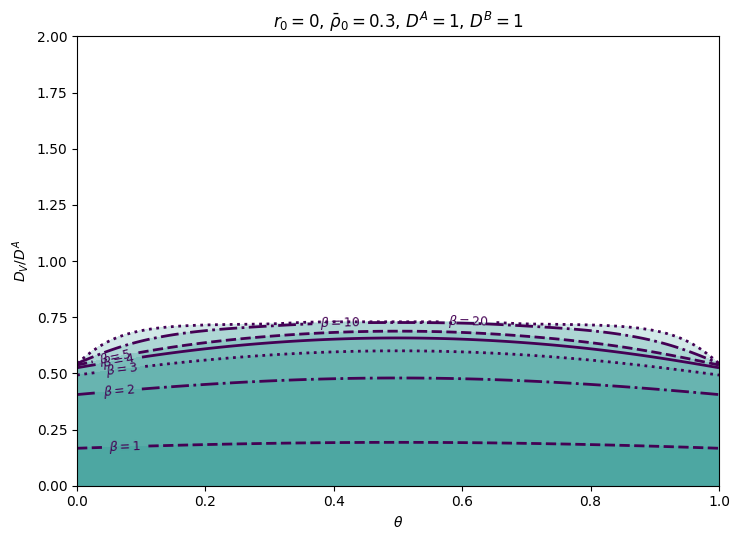

In [2]:
#!/usr/bin/env python3
"""
Tree-level critical surfaces of the Schelling--Voter hydrodynamic theory.

Default example:
    kappa(theta) = [[1-theta, theta],
                    [theta, 1-theta]]
    D_A = D_B = 1
    x axis: theta in [0,1]
    y axis: D_V / D_A
    several beta values shown as separate critical curves.

The script uses the exact microscopic response matrix Theta^{ab}(rho)
and the linear q^2 hydrodynamic matrix J.  The long-wavelength stability
boundary is r0 = min Re eig(J) = 0.  For the stationary Model-B branch one
may instead plot det(J)=0 subject to Tr(J)>0.

Dependencies: numpy, matplotlib.
"""

from dataclasses import dataclass, replace
from math import factorial
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt


# ======================================================================
# USER CONFIGURATION
# ======================================================================

X_PARAM = "theta"
Y_PARAM = "Dv_ratio"

X_RANGE = (0.0, 1.0)
Y_RANGE = (0.0, 2.0)

NX = 201
NY = 201

BETA_VALUES = [0.5, 1.0, 2.0, 3.0, 4.0, 5.0, 10.0, 20.0]

# "r0"         : min Re eig(J) = 0
# "stationary" : det(J) = 0, only where Tr(J) > 0
CRITERION = "r0"

# Baseline parameters. Parameters selected as X_PARAM or Y_PARAM are
# overwritten by the scan.
FIXED = {
    "D_A": 1.0,
    "D_B": 1.0,
    "Dv_ratio": 0.0,
    "beta": 1.0,
    "theta": 0.6,
    "rho_0": 0.30,
    "rho_A": 0.35,
    "rho_B": 0.35,
}

# If True, use rho_A=rho_B=(1-rho_0)/2.
# If False, use FIXED["rho_A"] and FIXED["rho_B"].
SYMMETRIC_BACKGROUND = True

OUTPUT_FILE = "../images/critical_surface_theta_Dv.png"
SHOW_FIGURE = False


# ======================================================================
# MODEL
# ======================================================================

@dataclass
class Params:
    D_A: float
    D_B: float
    D_V: float
    beta: float
    theta: float
    rho_A: float
    rho_B: float

    @property
    def rho_0(self):
        return 1.0 - self.rho_A - self.rho_B


def kappa_from_theta(theta):
    """Requested reciprocal one-parameter interaction matrix."""
    return np.array([
        [theta, theta-1.0],
        [theta-1.0, theta],
    ], dtype=float)


def multinomial3(n, i, j):
    k = n - i - j
    if min(i, j, k) < 0:
        return 0
    return factorial(n) // (factorial(i)*factorial(j)*factorial(k))


def theta_matrix(beta, kappa, rho_A, rho_B):
    r"""Exact finite-spectator response matrix Theta^{ab}(rho).

    Theta^{ab} = < tanh[beta/2 (kappa^{ab}+Delta)]
                   - tanh[beta/2 Delta] >,

    Delta=(m_A-n_A)kappa^{aA}+(m_B-n_B)kappa^{aB},
    with two destination-side and three source-side spectators.
    """
    rho_0 = 1.0 - rho_A - rho_B
    if rho_A < 0 or rho_B < 0 or rho_0 < 0:
        return np.full((2, 2), np.nan)

    T = np.zeros((2, 2), dtype=float)

    for mA in range(3):
        for mB in range(3-mA):
            m0 = 2-mA-mB
            pm = (multinomial3(2, mA, mB)
                  * rho_A**mA * rho_B**mB * rho_0**m0)

            for nA in range(4):
                for nB in range(4-nA):
                    n0 = 3-nA-nB
                    pn = (multinomial3(3, nA, nB)
                          * rho_A**nA * rho_B**nB * rho_0**n0)
                    weight = pm*pn
                    if weight == 0:
                        continue

                    for a in range(2):
                        delta = ((mA-nA)*kappa[a, 0]
                                 + (mB-nB)*kappa[a, 1])
                        t0 = np.tanh(0.5*beta*delta)
                        for b in range(2):
                            t1 = np.tanh(0.5*beta*(delta+kappa[a, b]))
                            T[a, b] += weight*(t1-t0)
    return T


@lru_cache(maxsize=None)
def cached_theta(beta, theta, rho_A, rho_B):
    """Cache Theta; useful when scanning D_V at fixed beta, theta and density."""
    return theta_matrix(beta, kappa_from_theta(theta), rho_A, rho_B)


def linear_matrix_J(p):
    """Linear q^2 matrix about a homogeneous state."""
    rA, rB, r0 = p.rho_A, p.rho_B, p.rho_0
    if min(rA, rB, r0) < -1e-12:
        return np.full((2, 2), np.nan)

    Theta = cached_theta(float(p.beta), float(p.theta), float(rA), float(rB))

    J = np.array([
        [p.D_A*(1-rB) + p.D_V*rB
         - 10*p.D_A*r0*rA*Theta[0, 0],
         p.D_A*rA - p.D_V*rA
         - 10*p.D_A*r0*rA*Theta[0, 1]],

        [p.D_B*rB - p.D_V*rB
         - 10*p.D_B*r0*rB*Theta[1, 0],
         p.D_B*(1-rA) + p.D_V*rA
         - 10*p.D_B*r0*rB*Theta[1, 1]],
    ], dtype=float)

    return J


def r0_value(p):
    J = linear_matrix_J(p)
    if not np.all(np.isfinite(J)):
        return np.nan
    return float(np.min(np.real(np.linalg.eigvals(J))))


def stationary_value(p):
    J = linear_matrix_J(p)
    if not np.all(np.isfinite(J)):
        return np.nan
    if np.trace(J) <= 0:
        return np.nan
    return float(np.linalg.det(J))


def critical_value(p):
    if CRITERION == "r0":
        return r0_value(p)
    if CRITERION == "stationary":
        return stationary_value(p)
    raise ValueError("CRITERION must be 'r0' or 'stationary'.")


# ======================================================================
# PARAMETER SCANNING
# ======================================================================

def initial_params():
    DA = FIXED["D_A"]
    DB = FIXED["D_B"]
    if SYMMETRIC_BACKGROUND:
        r0 = FIXED["rho_0"]
        rA = rB = 0.5*(1-r0)
    else:
        rA = FIXED["rho_A"]
        rB = FIXED["rho_B"]

    return Params(
        D_A=DA,
        D_B=DB,
        D_V=FIXED["Dv_ratio"]*DA,
        beta=FIXED["beta"],
        theta=FIXED["theta"],
        rho_A=rA,
        rho_B=rB,
    )


def set_parameter(p, name, value):
    """Add new scan parameters here if needed."""
    if name == "theta":
        return replace(p, theta=value)
    if name == "beta":
        return replace(p, beta=value)
    if name == "D_A":
        return replace(p, D_A=value)
    if name == "D_B":
        return replace(p, D_B=value)
    if name == "D_V":
        return replace(p, D_V=value)
    if name == "Dv_ratio":
        return replace(p, D_V=value*p.D_A)
    if name == "rho_0":
        rA = rB = 0.5*(1-value)
        return replace(p, rho_A=rA, rho_B=rB)
    if name == "rho_A":
        return replace(p, rho_A=value)
    if name == "rho_B":
        return replace(p, rho_B=value)
    raise ValueError(f"Unsupported scan parameter: {name}")


def axis_label(name):
    labels = {
        "theta": r"$\theta$",
        "beta": r"$\beta$",
        "D_A": r"$D^A$",
        "D_B": r"$D^B$",
        "D_V": r"$D_V$",
        "Dv_ratio": r"$D_V/D^A$",
        "rho_0": r"$\rho_0^{(0)}$",
        "rho_A": r"$\rho_A^{(0)}$",
        "rho_B": r"$\rho_B^{(0)}$",
    }
    return labels.get(name, name)


def evaluate_grid(base, xs, ys):
    Z = np.full((len(ys), len(xs)), np.nan)
    for iy, y in enumerate(ys):
        py = set_parameter(base, Y_PARAM, float(y))
        for ix, x in enumerate(xs):
            pxy = set_parameter(py, X_PARAM, float(x))
            Z[iy, ix] = critical_value(pxy)
    return Z


# ======================================================================
# PLOT
# ======================================================================

def main():
    base0 = initial_params()
    xs = np.linspace(*X_RANGE, NX)
    ys = np.linspace(*Y_RANGE, NY)
    X, Y = np.meshgrid(xs, ys)

    fig, ax = plt.subplots(figsize=(7.5, 5.5))

    line_styles = ["-", "--", "-.", ":"]
    for ibeta, beta in enumerate(BETA_VALUES):
        base = replace(base0, beta=float(beta))
        Z = evaluate_grid(base, xs, ys)
        Z_masked = np.ma.masked_invalid(Z)

        finite_Z = Z[np.isfinite(Z)]

        print(
            beta,
            np.nanmin(Z),
            np.nanmax(Z),
        )

        if finite_Z.size > 0 and np.min(finite_Z) < 0.0:
            zmin = np.min(finite_Z)

            ax.contourf(
                X,
                Y,
                Z_masked,
                levels=[zmin, 0.0],
                alpha=0.20,
            )

        # Shade unstable side of the critical curve.
        ax.contourf(
            X,
            Y,
            Z_masked,
            levels=[-np.inf, 0.0],
            alpha=0.12,
        )

        # Draw the critical curve on top.
        cs = ax.contour(
            X,
            Y,
            Z,
            levels=[0.0],
            linewidths=2.0,   
            linestyles=line_styles[ibeta % len(line_styles)],
        )

        # cs = ax.contour(
        #     X, Y, Z, levels=[0.0], linewidths=2.0,
        #     linestyles=line_styles[ibeta % len(line_styles)],
        # )
        if cs.allsegs[0]:
            ax.clabel(
                cs, levels=[0.0],
                fmt={0.0: rf"$\beta={beta:g}$"},
                inline=True, fontsize=9,
            )

    ax.set_xlabel(axis_label(X_PARAM))
    ax.set_ylabel(axis_label(Y_PARAM))
    ax.set_xlim(*X_RANGE)
    ax.set_ylim(*Y_RANGE)

    if CRITERION == "r0":
        branch = r"$r_0=0$"
    else:
        branch = r"$\det\mathbb{J}=0,\ \mathrm{Tr}\mathbb{J}>0$"

    ax.set_title(
        branch
        + rf", $\bar \rho_0={base0.rho_0:g}$, "
        + rf"$D^A={base0.D_A:g}$, $D^B={base0.D_B:g}$"
    )

    fig.tight_layout()
    fig.savefig(OUTPUT_FILE, dpi=250)
    print(f"Saved: {OUTPUT_FILE}")
    print(f"Background: rho_A={base0.rho_A:g}, rho_B={base0.rho_B:g}, rho_0={base0.rho_0:g}")

    if SHOW_FIGURE:
        plt.show()


if __name__ == "__main__":
    main()


In [17]:

param = initial_params()
p = set_parameter(param, "beta", 0.63)
p

Params(D_A=1.0, D_B=1.0, D_V=0.0, beta=0.63, theta=0.6, rho_A=0.35, rho_B=0.35)

In [18]:
kappa_from_theta(0.6)

array([[ 0.6, -0.4],
       [-0.4,  0.6]])

In [19]:
 r0_value(p)

-0.0034958433842536274

# Plot the different regimes $\beta$ vs $D_v$ 

segregating r0 range: -0.05066111466981768 0.1 TrJ range: 0.03230054587902362 0.2 detJ range: -0.0042066434049448445 0.010000000000000004 disc range: -6.938893903907228e-18 0.0179292931155249
integrating r0 range: -0.034702056315182236 0.1 TrJ range: 0.028720541736521145 0.2 detJ range: -0.004630038511308127 0.010000000000000004 disc range: -6.938893903907228e-18 0.028265899405984722
migrating r0 range: -0.0023725843217288697 0.1 TrJ range: -0.0047451686434577395 0.2 detJ range: 9.326798495443194e-05 0.010000000000000004 disc range: -0.00543276624988855 0.004900000000000005
well-mixed r0 range: 0.029999999999999985 0.1 TrJ range: 0.13 0.2 detJ range: 0.002999999999999999 0.010000000000000004 disc range: -6.938893903907228e-18 0.004900000000000005
Saved: ../images/critical_surfaces_regimes_beta_Dv.pdf


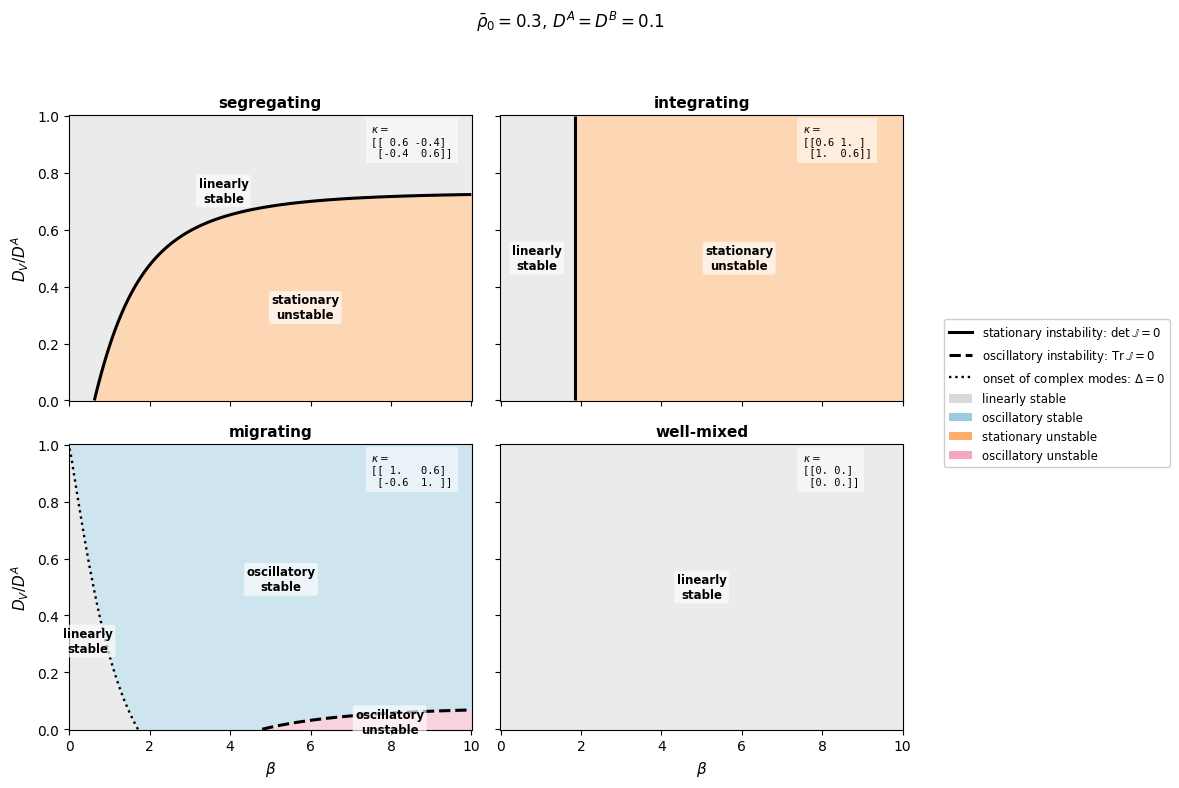

In [3]:
#!/usr/bin/env python3
"""
Tree-level critical surfaces of the Schelling--Voter hydrodynamic theory.

Default example:
    kappa(theta) = [[1-theta, theta],
                    [theta, 1-theta]]
    D_A = D_B = 1
    x axis: theta in [0,1]
    y axis: D_V / D_A
    several beta values shown as separate critical curves.

The script uses the exact microscopic response matrix Theta^{ab}(rho)
and the linear q^2 hydrodynamic matrix J.  The long-wavelength stability
boundary is r0 = min Re eig(J) = 0.  For the stationary Model-B branch one
may instead plot det(J)=0 subject to Tr(J)>0.

Dependencies: numpy, matplotlib.
"""
from matplotlib.lines import Line2D
from dataclasses import dataclass, replace
from math import factorial
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap, BoundaryNorm



# ============================================================================
# USER CONFIGURATION
# ============================================================================

REGIMES = {
    "segregating": np.array([
        [ 0.6, -0.4],
        [-0.4,  0.6],
    ]),
    "integrating": np.array([
        [0.6, 1.0],
        [1.0, 0.6],
    ]),
    "migrating": np.array([
        [ 1.0, 0.6],
        [-0.6, 1.0],
    ]),
    "well-mixed": np.array([
        [0.0, 0.0],
        [0.0, 0.0],
    ]),
}

# Scan beta against D_V / D_A
X_RANGE = (0.0, 10.0)
Y_RANGE = (0.0, 1.0)

NX = 301
NY = 301

# D_A = D_B = 1 fixes the time scale.
D_A = 0.1
D_B = 0.1

# Homogeneous background
RHO_0 = 0.30
RHO_A = 0.5 * (1.0 - RHO_0)
RHO_B = 0.5 * (1.0 - RHO_0)

# Either:
#   "r0"         -> full long-wavelength stability boundary
#   "stationary" -> det J = 0 with Tr J > 0
CRITERION = "stationary"

OUTPUT_FILE = "../images/critical_surfaces_regimes_beta_Dv.pdf"
SHOW_FIGURE = True


# ======================================================================
# MODEL
# ======================================================================
@dataclass
class Params:
    D_A: float = 0.1
    D_B: float = 0.1
    D_V: float = 0.0
    beta: float = 1.0
    rho_A: float = 0.35
    rho_B: float = 0.35

    @property
    def rho_0(self):
        return 1.0 - self.rho_A - self.rho_B

    @property
    def Dv_ratio(self):
        return self.D_V / self.D_A
    


def kappa_from_theta(theta):
    """Requested reciprocal one-parameter interaction matrix."""
    return np.array([
        [theta, 1.0-theta],
        [1.0-theta, theta],
    ], dtype=float)


def multinomial3(n, i, j):
    k = n - i - j
    if min(i, j, k) < 0:
        return 0
    return factorial(n) // (factorial(i)*factorial(j)*factorial(k))


def theta_matrix(beta, kappa, rho_A, rho_B):
    r"""Exact finite-spectator response matrix Theta^{ab}(rho).

    Theta^{ab} = < tanh[beta/2 (kappa^{ab}+Delta)]
                   - tanh[beta/2 Delta] >,

    Delta=(m_A-n_A)kappa^{aA}+(m_B-n_B)kappa^{aB},
    with two destination-side and three source-side spectators.
    """
    rho_0 = 1.0 - rho_A - rho_B
    if rho_A < 0 or rho_B < 0 or rho_0 < 0:
        return np.full((2, 2), np.nan)

    T = np.zeros((2, 2), dtype=float)

    for mA in range(3):
        for mB in range(3-mA):
            m0 = 2-mA-mB
            pm = (multinomial3(2, mA, mB)
                  * rho_A**mA * rho_B**mB * rho_0**m0)

            for nA in range(4):
                for nB in range(4-nA):
                    n0 = 3-nA-nB
                    pn = (multinomial3(3, nA, nB)
                          * rho_A**nA * rho_B**nB * rho_0**n0)
                    weight = pm*pn
                    if weight == 0:
                        continue

                    for a in range(2):
                        delta = ((mA-nA)*kappa[a, 0]
                                 + (mB-nB)*kappa[a, 1])
                        t0 = np.tanh(0.5*beta*delta)
                        for b in range(2):
                            t1 = np.tanh(0.5*beta*(delta+kappa[a, b]))
                            T[a, b] += weight*(t1-t0)
    return T


@lru_cache(maxsize=None)
def cached_theta(beta, theta, rho_A, rho_B):
    """Cache Theta; useful when scanning D_V at fixed beta, theta and density."""
    return theta_matrix(beta, kappa_from_theta(theta), rho_A, rho_B)


def linear_matrix_J(p: Params, kappa: np.ndarray) -> np.ndarray:
    """Linear q^2 transport matrix J around the homogeneous state."""

    rho_A = p.rho_A
    rho_B = p.rho_B
    rho_0 = p.rho_0

    if rho_A < 0.0 or rho_B < 0.0 or rho_0 < -1e-14:
        return np.full((2, 2), np.nan)

    Theta = theta_matrix(
        beta=p.beta,
        kappa=kappa,
        rho_A=rho_A,
        rho_B=rho_B,
    )

    J = np.empty((2, 2), dtype=float)

    J[0, 0] = (
        p.D_A * (1.0 - rho_B)
        + p.D_V * rho_B
        - 10.0 * p.D_A * rho_0 * rho_A * Theta[0, 0]
    )

    J[0, 1] = (
        p.D_A * rho_A
        - p.D_V * rho_A
        - 10.0 * p.D_A * rho_0 * rho_A * Theta[0, 1]
    )

    J[1, 0] = (
        p.D_B * rho_B
        - p.D_V * rho_B
        - 10.0 * p.D_B * rho_0 * rho_B * Theta[1, 0]
    )

    J[1, 1] = (
        p.D_B * (1.0 - rho_A)
        + p.D_V * rho_A
        - 10.0 * p.D_B * rho_0 * rho_B * Theta[1, 1]
    )

    return J


def r0_value(p: Params, kappa: np.ndarray) -> float:
    J = linear_matrix_J(p, kappa)

    if not np.all(np.isfinite(J)):
        return np.nan

    eigvals = np.linalg.eigvals(J)

    return float(np.min(np.real(eigvals)))


def stationary_criterion(p: Params, kappa: np.ndarray) -> float:
    J = linear_matrix_J(p, kappa)

    if not np.all(np.isfinite(J)):
        return np.nan

    trJ = np.trace(J)

    # Only retain the stationary Model-B branch
    if trJ <= 0.0:
        return np.nan

    return float(np.linalg.det(J))


def critical_function(
    p: Params,
    kappa: np.ndarray,
    criterion: str,
) -> float:

    if criterion == "r0":
        return r0_value(p, kappa)

    if criterion == "stationary":
        return stationary_criterion(p, kappa)

    raise ValueError(f"Unknown criterion: {criterion}")


# ======================================================================
# PARAMETER SCANNING
# ======================================================================

def initial_params():
    DA = FIXED["D_A"]
    DB = FIXED["D_B"]
    if SYMMETRIC_BACKGROUND:
        r0 = FIXED["rho_0"]
        rA = rB = 0.5*(1-r0)
    else:
        rA = FIXED["rho_A"]
        rB = FIXED["rho_B"]

    return Params(
        D_A=DA,
        D_B=DB,
        D_V=FIXED["Dv_ratio"]*DA,
        beta=FIXED["beta"],
        theta=FIXED["theta"],
        rho_A=rA,
        rho_B=rB,
    )


def set_parameter(p, name, value):
    """Add new scan parameters here if needed."""
    if name == "theta":
        return replace(p, theta=value)
    if name == "beta":
        return replace(p, beta=value)
    if name == "D_A":
        return replace(p, D_A=value)
    if name == "D_B":
        return replace(p, D_B=value)
    if name == "D_V":
        return replace(p, D_V=value)
    if name == "Dv_ratio":
        return replace(p, D_V=value*p.D_A)
    if name == "rho_0":
        rA = rB = 0.5*(1-value)
        return replace(p, rho_A=rA, rho_B=rB)
    if name == "rho_A":
        return replace(p, rho_A=value)
    if name == "rho_B":
        return replace(p, rho_B=value)
    raise ValueError(f"Unsupported scan parameter: {name}")


def axis_label(name):
    labels = {
        "theta": r"$\theta$",
        "beta": r"$\beta$",
        "D_A": r"$D^A$",
        "D_B": r"$D^B$",
        "D_V": r"$D_V$",
        "Dv_ratio": r"$D_V/D^A$",
        "rho_0": r"$\rho_0^{(0)}$",
        "rho_A": r"$\rho_A^{(0)}$",
        "rho_B": r"$\rho_B^{(0)}$",
    }
    return labels.get(name, name)


def evaluate_grid(
    base: Params,
    kappa: np.ndarray,
    beta_values: np.ndarray,
    dv_values: np.ndarray,
):

    Z = np.full(
        (len(dv_values), len(beta_values)),
        np.nan,
        dtype=float,
    )

    for iy, dv_ratio in enumerate(dv_values):

        for ix, beta in enumerate(beta_values):

            p = replace(
                base,
                beta=float(beta),
                D_V=float(dv_ratio) * base.D_A,
            )

            Z[iy, ix] = critical_function(
                p,
                kappa,
                CRITERION,
            )

    return Z

def evaluate_stability_grid(
    base: Params,
    kappa: np.ndarray,
    beta_values: np.ndarray,
    dv_values: np.ndarray,
):
    """
    Evaluate the three relevant long-wavelength stability diagnostics:

        detJ          = det(J)
        trJ           = Tr(J)
        discriminant  = Tr(J)^2 - 4 det(J)

    Critical curves:
        detJ = 0, TrJ > 0       stationary / segregation instability
        trJ  = 0, detJ > 0      oscillatory / migration instability
        discriminant = 0        onset of complex eigenvalues
    """

    shape = (len(dv_values), len(beta_values))

    detJ = np.full(shape, np.nan)
    trJ = np.full(shape, np.nan)
    discr = np.full(shape, np.nan)

    # Masked quantities used specifically for drawing the two instability lines
    stationary = np.full(shape, np.nan)
    oscillatory = np.full(shape, np.nan)

    for iy, dv_ratio in enumerate(dv_values):

        for ix, beta in enumerate(beta_values):

            p = replace(
                base,
                beta=float(beta),
                D_V=float(dv_ratio) * base.D_A,
            )

            J = linear_matrix_J(p, kappa)

            if not np.all(np.isfinite(J)):
                continue

            tr = float(np.trace(J))
            det = float(np.linalg.det(J))
            disc = tr**2 - 4.0 * det

            trJ[iy, ix] = tr
            detJ[iy, ix] = det
            discr[iy, ix] = disc

            # Stationary Model-B-like instability:
            # one real eigenvalue passes through zero.
            if tr > 0.0:
                stationary[iy, ix] = det

            # Oscillatory instability:
            # complex conjugate pair crosses Re(lambda)=0.
            if det > 0.0:
                oscillatory[iy, ix] = tr

    return {
        "trace": trJ,
        "det": detJ,
        "discriminant": discr,
        "stationary": stationary,
        "oscillatory": oscillatory,
    }

    

# ======================================================================
# PLOT
# ======================================================================
def main():

    TOL = 1e-10

    # ============================================================
    # SETUP
    # ============================================================

    base = Params(
        D_A=D_A,
        D_B=D_B,
        D_V=0.0,
        beta=1.0,
        rho_A=RHO_A,
        rho_B=RHO_B,
    )

    betas = np.linspace(*X_RANGE, NX)
    dvs = np.linspace(*Y_RANGE, NY)

    BETA, DV = np.meshgrid(betas, dvs)

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(11.5, 8.0),
        sharex=True,
        sharey=True,
    )

    axes = axes.ravel()


    # ============================================================
    # COMMON PHASE COLORS
    # ============================================================

    phase_colors = [
        "#d9d9d9",   # stable, real
        "#9ecae1",   # stable, oscillatory
        "#fdae6b",   # stationary unstable
        "#f4a6c1",   # oscillatory unstable
    ]

    cmap = ListedColormap(phase_colors)

    norm = BoundaryNorm(
        [-0.5, 0.5, 1.5, 2.5, 3.5],
        cmap.N,
    )


    # ============================================================
    # HELPER: PLACE LABEL INSIDE A REGION
    # ============================================================

    def place_region_label(ax, mask, text, min_fraction=0.015):
        """
        Put text at an actual grid point inside the region.

        Very small regions are skipped so that labels do not clutter
        the plot.
        """

        iy, ix = np.where(mask)

        if len(ix) == 0:
            return

        # Skip tiny regions
        if len(ix) / mask.size < min_fraction:
            return

        beta_points = BETA[iy, ix]
        dv_points = DV[iy, ix]

        beta_c = np.mean(beta_points)
        dv_c = np.mean(dv_points)

        # Normalize distances because beta and Dv/D_A have
        # very different numerical ranges.
        dbeta = (
            (beta_points - beta_c)
            / (X_RANGE[1] - X_RANGE[0])
        )

        ddv = (
            (dv_points - dv_c)
            / (Y_RANGE[1] - Y_RANGE[0])
        )

        i_best = np.argmin(dbeta**2 + ddv**2)

        ax.text(
            beta_points[i_best],
            dv_points[i_best],
            text,
            ha="center",
            va="center",
            fontsize=8.5,
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.20",
                facecolor="white",
                edgecolor="none",
                alpha=0.65,
            ),
            zorder=10,
        )


    # ============================================================
    # LOOP OVER THE FOUR REGIMES
    # ============================================================

    for ax, (regime, kappa) in zip(
        axes,
        REGIMES.items(),
    ):

        data = evaluate_stability_grid(
            base,
            kappa,
            betas,
            dvs,
        )

        tr = data["trace"]
        det = data["det"]
        disc = data["discriminant"]


        # --------------------------------------------------------
        # r0 = minimum real part of the two eigenvalues
        #
        # If disc >= 0:
        #
        #     lambda_- = (Tr J - sqrt(disc))/2
        #
        # If disc < 0:
        #
        #     Re lambda = Tr J / 2
        #
        # Treat tiny negative discriminants as zero.
        # --------------------------------------------------------

        disc_for_sqrt = np.maximum(disc, 0.0)

        r0 = np.where(
            disc >= -TOL,
            0.5 * (
                tr - np.sqrt(disc_for_sqrt)
            ),
            0.5 * tr,
        )


        # ========================================================
        # CLASSIFY FOUR REGIONS
        # ========================================================

        # (i) Linearly stable, purely relaxational
        stable_real = (
            (r0 > TOL)
            & (disc >= -TOL)
        )

        # (ii) Linearly stable, oscillatory
        stable_oscillatory = (
            (r0 > TOL)
            & (disc < -TOL)
        )

        # (iii) Stationary unstable:
        # real eigenvalues and at least one negative mode
        stationary_unstable = (
            (r0 < -TOL)
            & (disc >= -TOL)
        )

        # (iv) Oscillatory unstable:
        # complex pair with negative real part
        oscillatory_unstable = (
            (r0 < -TOL)
            & (disc < -TOL)
        )


        # ========================================================
        # BUILD PHASE MAP
        # ========================================================

        phase = np.full_like(
            tr,
            np.nan,
            dtype=float,
        )

        phase[stable_real] = 0
        phase[stable_oscillatory] = 1
        phase[stationary_unstable] = 2
        phase[oscillatory_unstable] = 3

        phase_masked = np.ma.masked_invalid(phase)


        # ========================================================
        # COLORED REGIONS
        # ========================================================

        ax.pcolormesh(
            BETA,
            DV,
            phase_masked,
            cmap=cmap,
            norm=norm,
            shading="auto",
            alpha=0.50,
            zorder=0,
        )


        # ========================================================
        # BOUNDARY 1:
        # stationary instability
        #
        # det J = 0, Tr J > 0
        # ========================================================

        det_stationary = np.where(
            tr > TOL,
            det,
            np.nan,
        )

        finite = det_stationary[
            np.isfinite(det_stationary)
        ]

        if (
            finite.size > 0
            and np.min(finite) < -TOL
            and np.max(finite) > TOL
        ):
            ax.contour(
                BETA,
                DV,
                det_stationary,
                levels=[0.0],
                colors="black",
                linewidths=2.2,
                linestyles="-",
                zorder=5,
            )


        # ========================================================
        # BOUNDARY 2:
        # oscillatory instability / Hopf boundary
        #
        # Tr J = 0, det J > 0, disc < 0
        # ========================================================

        trace_hopf = np.where(
            (det > TOL)
            & (disc < -TOL),
            tr,
            np.nan,
        )

        finite = trace_hopf[
            np.isfinite(trace_hopf)
        ]

        if (
            finite.size > 0
            and np.min(finite) < -TOL
            and np.max(finite) > TOL
        ):
            ax.contour(
                BETA,
                DV,
                trace_hopf,
                levels=[0.0],
                colors="black",
                linewidths=2.2,
                linestyles="--",
                zorder=5,
            )


        # ========================================================
        # BOUNDARY 3:
        # onset of complex eigenvalues
        #
        # Delta = (Tr J)^2 - 4 det J = 0
        # ========================================================

        finite = disc[
            np.isfinite(disc)
        ]

        if (
            finite.size > 0
            and np.min(finite) < -TOL
            and np.max(finite) > TOL
        ):
            ax.contour(
                BETA,
                DV,
                disc,
                levels=[0.0],
                colors="black",
                linewidths=1.7,
                linestyles=":",
                zorder=5,
            )


        # ========================================================
        # REGION LABELS
        # ========================================================

        place_region_label(
            ax,
            stable_real,
            "linearly\nstable",
        )

        place_region_label(
            ax,
            stable_oscillatory,
            "oscillatory\nstable",
        )

        place_region_label(
            ax,
            stationary_unstable,
            "stationary\nunstable",
        )

        place_region_label(
            ax,
            oscillatory_unstable,
            "oscillatory\nunstable",
        )


        # ========================================================
        # PANEL TITLE + KAPPA
        # ========================================================

        ax.set_title(
            regime,
            fontsize=11,
            fontweight="bold",
        )

        ax.text(
            0.75,
            0.97,
            r"$\kappa =$"
            + "\n"
            + str(kappa),
            transform=ax.transAxes,
            verticalalignment="top",
            horizontalalignment="left",
            fontsize=7.5,
            family="monospace",
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.55,
            ),
        )


        # ========================================================
        # DIAGNOSTICS
        # ========================================================

        print(
            regime,
            "r0 range:",
            np.nanmin(r0),
            np.nanmax(r0),
            "TrJ range:",
            np.nanmin(tr),
            np.nanmax(tr),
            "detJ range:",
            np.nanmin(det),
            np.nanmax(det),
            "disc range:",
            np.nanmin(disc),
            np.nanmax(disc),
        )


    # ============================================================
    # AXIS LABELS
    # ============================================================

    axes[2].set_xlabel(
        r"$\beta$",
        fontsize=11,
    )

    axes[3].set_xlabel(
        r"$\beta$",
        fontsize=11,
    )

    axes[0].set_ylabel(
        r"$D_V/D^A$",
        fontsize=11,
    )

    axes[2].set_ylabel(
        r"$D_V/D^A$",
        fontsize=11,
    )


    # ============================================================
    # SHARED LEGEND
    # ============================================================

    line_handles = [
        Line2D(
            [0], [0],
            color="black",
            linewidth=2.2,
            linestyle="-",
            label=r"stationary instability: "
                  r"$\det\mathbb{J}=0$",
        ),

        Line2D(
            [0], [0],
            color="black",
            linewidth=2.2,
            linestyle="--",
            label=r"oscillatory instability: "
                  r"$\mathrm{Tr}\,\mathbb{J}=0$",
        ),

        Line2D(
            [0], [0],
            color="black",
            linewidth=1.7,
            linestyle=":",
            label=r"onset of complex modes: "
                  r"$\Delta=0$",
        ),
    ]

    phase_handles = [
        Patch(
            facecolor=phase_colors[0],
            edgecolor="none",
            label="linearly stable",
        ),

        Patch(
            facecolor=phase_colors[1],
            edgecolor="none",
            label="oscillatory stable",
        ),

        Patch(
            facecolor=phase_colors[2],
            edgecolor="none",
            label="stationary unstable",
        ),

        Patch(
            facecolor=phase_colors[3],
            edgecolor="none",
            label="oscillatory unstable",
        ),
    ]

    fig.legend(
        handles=line_handles + phase_handles,
        loc="center left",
        bbox_to_anchor=(0.82, 0.50),
        fontsize=8.5,
        framealpha=0.95,
    )


    # ============================================================
    # FIGURE TITLE
    # ============================================================

    fig.suptitle(
        rf"$\bar\rho_0={base.rho_0:g}$, "
        rf"$D^A=D^B={base.D_A:g}$",
        fontsize=12,
    )


    # Leave room at the right for the shared legend
    fig.tight_layout(
        rect=[0.0, 0.0, 0.81, 0.94]
    )

    fig.savefig(
        OUTPUT_FILE,
        dpi=300,
        bbox_inches="tight",
    )

    print(f"Saved: {OUTPUT_FILE}")

    if SHOW_FIGURE:
        plt.show()


if __name__ == "__main__":
    main()


# Explore the migrating regime

Saved: critical_beta_nonreciprocity.png
Trace range: -0.00681591380346646 0.13
det range: -0.0012249998515335547 0.002999999999999999
discriminant range: -0.00974581756865216 0.004900000000000005
r0 range: -0.03809048726833232 0.03258390864183207


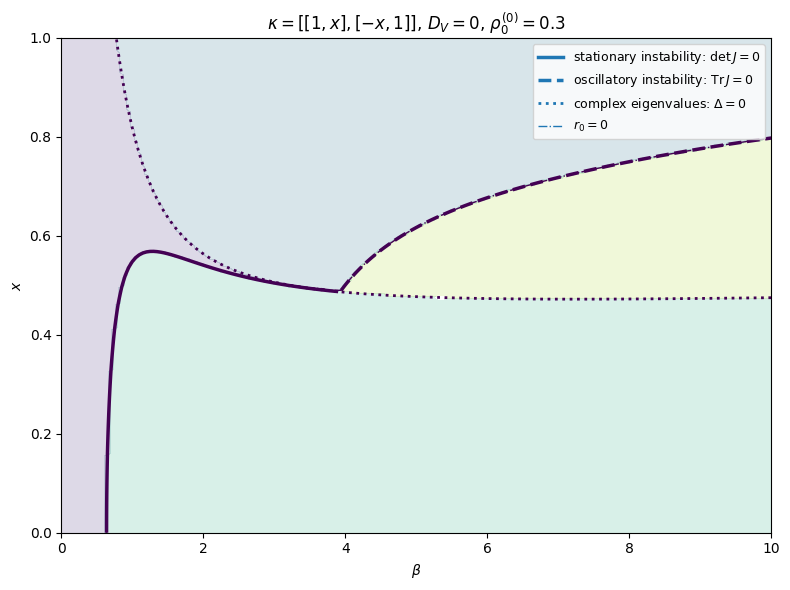

In [ ]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


TOL = 1e-10

# Scan ranges
BETA_RANGE = (0.0, 10.0)
X_RANGE = (0.0, 1.0)

N_BETA = 201
N_X = 201

# Fixed parameters
D_A = 0.1
D_B = 0.1
D_V = 0.0

RHO_0 = 0.30
RHO_A = 0.5 * (1.0 - RHO_0)
RHO_B = 0.5 * (1.0 - RHO_0)

OUTPUT_FILE = "../images/critical_beta_nonreciprocity.png"
SHOW_FIGURE = True


def kappa_from_x(x):
    """
    Non-reciprocal family

        kappa = [[ 1,  x],
                 [-x,  1]]
    """
    return np.array([
        [1.0,  x],
        [-x, 1.0],
    ])


def evaluate_beta_x_grid(base, betas, x_values):

    shape = (len(x_values), len(betas))

    trace = np.full(shape, np.nan)
    determinant = np.full(shape, np.nan)
    discriminant = np.full(shape, np.nan)
    r0 = np.full(shape, np.nan)

    for ix, x in enumerate(x_values):

        kappa = kappa_from_x(x)

        for ib, beta in enumerate(betas):

            p = replace(
                base,
                beta=float(beta),
                D_V=0.0,
            )

            J = linear_matrix_J(p, kappa)

            if not np.all(np.isfinite(J)):
                continue

            tr = float(np.trace(J))
            det = float(np.linalg.det(J))
            disc = tr**2 - 4.0 * det

            eig = np.linalg.eigvals(J)

            trace[ix, ib] = tr
            determinant[ix, ib] = det
            discriminant[ix, ib] = disc
            r0[ix, ib] = np.min(np.real(eig))

    return {
        "trace": trace,
        "det": determinant,
        "discriminant": discriminant,
        "r0": r0,
    }


def main():

    base = Params(
        D_A=D_A,
        D_B=D_B,
        D_V=0.0,
        beta=1.0,
        rho_A=RHO_A,
        rho_B=RHO_B,
    )

    betas = np.linspace(*BETA_RANGE, N_BETA)
    x_values = np.linspace(*X_RANGE, N_X)

    BETA, X = np.meshgrid(betas, x_values)

    data = evaluate_beta_x_grid(
        base,
        betas,
        x_values,
    )

    tr = data["trace"]
    det = data["det"]
    disc = data["discriminant"]
    r0 = data["r0"]


    # ============================================================
    # CLASSIFY THE FOUR REGIONS
    # ============================================================

    # 1. Stable, purely relaxational
    stable_real = (
        (tr > TOL)
        & (det > TOL)
        & (disc >= -TOL)
    )

    # 2. Stable, oscillatory
    stable_osc = (
        (tr > TOL)
        & (det > TOL)
        & (disc < -TOL)
    )

    # 3. Stationary instability
    #
    # For det < 0, the two eigenvalues are real and of opposite sign.
    stationary_unstable = (
        det < -TOL
    )

    # 4. Oscillatory instability
    #
    # Complex pair with negative real part.
    oscillatory_unstable = (
        (tr < -TOL)
        & (det > TOL)
        & (disc < -TOL)
    )


    # ============================================================
    # PLOT REGIONS
    # ============================================================

    fig, ax = plt.subplots(figsize=(8.0, 6.0))

    # Use integer phase labels:
    #
    # 0 = stable real
    # 1 = stable oscillatory
    # 2 = stationary unstable
    # 3 = oscillatory unstable

    phase = np.full_like(tr, np.nan)

    phase[stable_real] = 0
    phase[stable_osc] = 1
    phase[stationary_unstable] = 2
    phase[oscillatory_unstable] = 3

    # Light background shading for all four regions
    ax.contourf(
        BETA,
        X,
        phase,
        levels=[-0.5, 0.5, 1.5, 2.5, 3.5],
        alpha=0.18,
    )


    # ============================================================
    # BOUNDARY 1:
    # stationary instability
    #
    # det J = 0, Tr J > 0
    # ============================================================

    det_stationary = np.where(
        tr > TOL,
        det,
        np.nan,
    )

    if (
        np.nanmin(det_stationary) < -TOL
        and np.nanmax(det_stationary) > TOL
    ):
        ax.contour(
            BETA,
            X,
            det_stationary,
            levels=[0.0],
            linewidths=2.5,
            linestyles="-",
        )


    # ============================================================
    # BOUNDARY 2:
    # oscillatory instability
    #
    # Tr J = 0, det J > 0, disc < 0
    # ============================================================

    trace_hopf = np.where(
        (det > TOL) & (disc < -TOL),
        tr,
        np.nan,
    )

    if (
        np.any(np.isfinite(trace_hopf))
        and np.nanmin(trace_hopf) < -TOL
        and np.nanmax(trace_hopf) > TOL
    ):
        ax.contour(
            BETA,
            X,
            trace_hopf,
            levels=[0.0],
            linewidths=2.5,
            linestyles="--",
        )


    # ============================================================
    # BOUNDARY 3:
    # onset of complex eigenvalues
    #
    # discriminant = 0
    # ============================================================

    if (
        np.nanmin(disc) < -TOL
        and np.nanmax(disc) > TOL
    ):
        ax.contour(
            BETA,
            X,
            disc,
            levels=[0.0],
            linewidths=2.0,
            linestyles=":",
        )


    # ============================================================
    # OPTIONAL:
    # the complete r0 = 0 boundary
    #
    # This should coincide with either the stationary or Hopf
    # instability boundaries above.
    # ============================================================

    if (
        np.nanmin(r0) < -TOL
        and np.nanmax(r0) > TOL
    ):
        ax.contour(
            BETA,
            X,
            r0,
            levels=[0.0],
            linewidths=1.0,
            linestyles="-.",
        )


    # ============================================================
    # LEGEND
    # ============================================================

    line_legend = [
        Line2D(
            [0], [0],
            linewidth=2.5,
            linestyle="-",
            label=r"stationary instability: $\det J=0$",
        ),
        Line2D(
            [0], [0],
            linewidth=2.5,
            linestyle="--",
            label=r"oscillatory instability: $\mathrm{Tr}\,J=0$",
        ),
        Line2D(
            [0], [0],
            linewidth=2.0,
            linestyle=":",
            label=r"complex eigenvalues: $\Delta=0$",
        ),
        Line2D(
            [0], [0],
            linewidth=1.0,
            linestyle="-.",
            label=r"$r_0=0$",
        ),
    ]

    ax.legend(
        handles=line_legend,
        fontsize=9,
        loc="best",
    )


    # ============================================================
    # AXES
    # ============================================================

    ax.set_xlabel(r"$\beta$")
    ax.set_ylabel(r"$x$")

    ax.set_xlim(*BETA_RANGE)
    ax.set_ylim(*X_RANGE)

    ax.set_title(
        r"$\kappa=$"  + "$[[1,x],[-x,1]]$, "
        + rf"$D_V=0$, "
        + rf"$\rho_0^{{(0)}}={RHO_0:g}$"
    )

    fig.tight_layout()

    fig.savefig(
        OUTPUT_FILE,
        dpi=250,
        bbox_inches="tight",
    )

    print(f"Saved: {OUTPUT_FILE}")

    print(
        "Trace range:",
        np.nanmin(tr),
        np.nanmax(tr),
    )

    print(
        "det range:",
        np.nanmin(det),
        np.nanmax(det),
    )

    print(
        "discriminant range:",
        np.nanmin(disc),
        np.nanmax(disc),
    )

    print(
        "r0 range:",
        np.nanmin(r0),
        np.nanmax(r0),
    )

    if SHOW_FIGURE:
        plt.show()


if __name__ == "__main__":
    main()

Trace range: -0.06466110300012706 1.3
det range: -0.12249994953079979 0.30000000000000004
discriminant range: -0.9739207666350342 0.4900000000000003
r0 range: -0.38069244233433963 0.3258390864183207
mode character range: -1.0000000000000002 -0.1502574934356896
Saved: ../images/pure_schelling_beta_x_phase_diagram.png


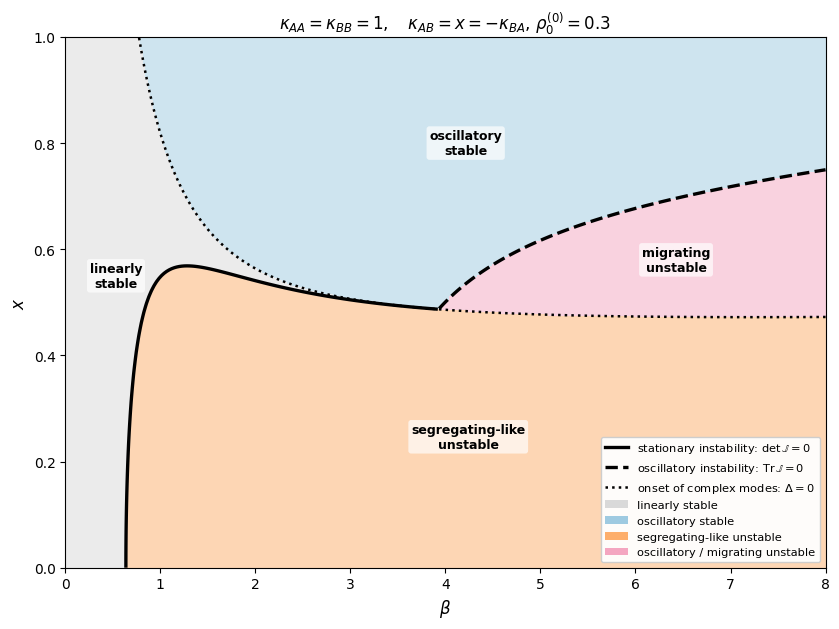

In [4]:
#!/usr/bin/env python3

"""
Pure Schelling tree-level phase diagram.

We scan

    kappa = [[ 1,  x],
             [-x,  1]]

in the (beta, x) plane, with D_V = 0.

The exact microscopic response matrix Theta^{ab}(rho) is used.

The linearized hydrodynamic matrix J determines the long-wavelength
eigenmodes.  We distinguish five regions:

    1. linearly stable, real modes
    2. linearly stable, oscillatory modes
    3. integrating-like stationary instability
    4. segregating-like stationary instability
    5. oscillatory/migrating instability

For a stationary unstable mode with right eigenvector v = (v_A,v_B),

    chi_v = 2 v_A v_B / (v_A^2 + v_B^2)

is used to classify the instability:

    chi_v > 0 : integrating-like
    chi_v < 0 : segregating-like

For an exactly A <-> B symmetric theory these reduce to the
symmetric (1,1) and antisymmetric (1,-1) modes, respectively.

Dependencies:
    numpy
    matplotlib
"""

from dataclasses import dataclass, replace
from math import factorial

import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# ============================================================================
# USER CONFIGURATION
# ============================================================================

BETA_RANGE = (0.0, 8.0)
X_RANGE = (0.0, 1.0)

N_BETA = 301
N_X = 301

# Overall time-scale normalization
D_A = 1.0
D_B = 1.0

# Pure Schelling
D_V = 0.0

# Symmetric homogeneous background
RHO_0 = 0.30
RHO_A = 0.5 * (1.0 - RHO_0)
RHO_B = 0.5 * (1.0 - RHO_0)

TOL = 1e-10

OUTPUT_FILE = "../images/pure_schelling_beta_x_phase_diagram.png"
SHOW_FIGURE = True


# ============================================================================
# PARAMETERS
# ============================================================================

@dataclass
class Params:
    D_A: float = 1.0
    D_B: float = 1.0
    D_V: float = 0.0

    beta: float = 1.0

    rho_A: float = 0.35
    rho_B: float = 0.35

    @property
    def rho_0(self):
        return 1.0 - self.rho_A - self.rho_B


# ============================================================================
# MICROSCOPIC INTERACTION MATRIX
# ============================================================================

def kappa_from_x(x):
    """
    Non-reciprocal one-parameter family

        kappa = [[ 1,  x],
                 [-x,  1]]
    """

    return np.array(
        [
            [1.0,  x],
            [-x,   1.0],
        ],
        dtype=float,
    )


# ============================================================================
# EXACT MICROSCOPIC THETA MATRIX
# ============================================================================

def multinomial3(n, i, j):
    """
    n! / [i! j! (n-i-j)!]
    """

    k = n - i - j

    if min(i, j, k) < 0:
        return 0

    return (
        factorial(n)
        // (
            factorial(i)
            * factorial(j)
            * factorial(k)
        )
    )


def theta_matrix(
    beta,
    kappa,
    rho_A,
    rho_B,
):
    r"""
    Exact finite-spectator response matrix Theta^{ab}(rho).

    For the square-lattice geometry used in the derivation,

        Theta^{ab}
        =
        <
            tanh[ beta/2 (Delta + kappa^{ab}) ]
            -
            tanh[ beta/2 Delta ]
        >,

    where

        Delta
        =
        (m_A-n_A) kappa^{aA}
        +
        (m_B-n_B) kappa^{aB}.

    The average is over:
        2 destination-side spectators
        3 source-side spectators

    with probabilities rho_A, rho_B, rho_0.
    """

    rho_0 = 1.0 - rho_A - rho_B

    if (
        rho_A < 0.0
        or rho_B < 0.0
        or rho_0 < 0.0
    ):
        return np.full((2, 2), np.nan)

    Theta = np.zeros(
        (2, 2),
        dtype=float,
    )

    # ------------------------------------------------------------------
    # Destination-side spectators: 2 sites
    # ------------------------------------------------------------------

    for mA in range(3):

        for mB in range(3 - mA):

            m0 = 2 - mA - mB

            p_m = (
                multinomial3(2, mA, mB)
                * rho_A**mA
                * rho_B**mB
                * rho_0**m0
            )

            # ----------------------------------------------------------
            # Source-side spectators: 3 sites
            # ----------------------------------------------------------

            for nA in range(4):

                for nB in range(4 - nA):

                    n0 = 3 - nA - nB

                    p_n = (
                        multinomial3(3, nA, nB)
                        * rho_A**nA
                        * rho_B**nB
                        * rho_0**n0
                    )

                    weight = p_m * p_n

                    if weight == 0.0:
                        continue

                    # --------------------------------------------------
                    # Species a whose hopping rate responds
                    # --------------------------------------------------

                    for a in range(2):

                        delta = (
                            (mA - nA) * kappa[a, 0]
                            +
                            (mB - nB) * kappa[a, 1]
                        )

                        t0 = np.tanh(
                            0.5 * beta * delta
                        )

                        # ----------------------------------------------
                        # Density species b being varied
                        # ----------------------------------------------

                        for b in range(2):

                            t1 = np.tanh(
                                0.5
                                * beta
                                * (
                                    delta
                                    + kappa[a, b]
                                )
                            )

                            Theta[a, b] += (
                                weight
                                * (t1 - t0)
                            )

    return Theta


# ============================================================================
# LINEARIZED HYDRODYNAMIC MATRIX
# ============================================================================

def linear_matrix_J(
    p: Params,
    kappa: np.ndarray,
):
    """
    Linear q^2 transport matrix around a homogeneous state.
    """

    rho_A = p.rho_A
    rho_B = p.rho_B
    rho_0 = p.rho_0

    if (
        rho_A < 0.0
        or rho_B < 0.0
        or rho_0 < -1e-14
    ):
        return np.full((2, 2), np.nan)

    Theta = theta_matrix(
        beta=p.beta,
        kappa=kappa,
        rho_A=rho_A,
        rho_B=rho_B,
    )

    J = np.empty(
        (2, 2),
        dtype=float,
    )

    # AA
    J[0, 0] = (
        p.D_A * (1.0 - rho_B)
        + p.D_V * rho_B
        - 10.0
        * p.D_A
        * rho_0
        * rho_A
        * Theta[0, 0]
    )

    # AB
    J[0, 1] = (
        p.D_A * rho_A
        - p.D_V * rho_A
        - 10.0
        * p.D_A
        * rho_0
        * rho_A
        * Theta[0, 1]
    )

    # BA
    J[1, 0] = (
        p.D_B * rho_B
        - p.D_V * rho_B
        - 10.0
        * p.D_B
        * rho_0
        * rho_B
        * Theta[1, 0]
    )

    # BB
    J[1, 1] = (
        p.D_B * (1.0 - rho_A)
        + p.D_V * rho_A
        - 10.0
        * p.D_B
        * rho_0
        * rho_B
        * Theta[1, 1]
    )

    return J


# ============================================================================
# GRID EVALUATION
# ============================================================================

def evaluate_beta_x_grid(
    base,
    betas,
    x_values,
):

    shape = (
        len(x_values),
        len(betas),
    )

    trace = np.full(
        shape,
        np.nan,
    )

    determinant = np.full(
        shape,
        np.nan,
    )

    discriminant = np.full(
        shape,
        np.nan,
    )

    r0 = np.full(
        shape,
        np.nan,
    )

    mode_character = np.full(
        shape,
        np.nan,
    )

    # ==================================================================
    # SCAN x
    # ==================================================================

    for ix, x in enumerate(x_values):

        kappa = kappa_from_x(x)

        # ==============================================================
        # SCAN beta
        # ==============================================================

        for ib, beta in enumerate(betas):

            p = replace(
                base,
                beta=float(beta),
                D_V=0.0,
            )

            J = linear_matrix_J(
                p,
                kappa,
            )

            if not np.all(np.isfinite(J)):
                continue

            tr = float(
                np.trace(J)
            )

            det = float(
                np.linalg.det(J)
            )

            disc = (
                tr**2
                - 4.0 * det
            )

            eigvals, eigvecs = np.linalg.eig(J)

            # ----------------------------------------------------------
            # Softest mode = eigenvalue with smallest real part
            # ----------------------------------------------------------

            i_soft = np.argmin(
                np.real(eigvals)
            )

            lam_soft = eigvals[i_soft]

            v_soft = eigvecs[
                :,
                i_soft,
            ]

            trace[ix, ib] = tr
            determinant[ix, ib] = det
            discriminant[ix, ib] = disc

            r0[ix, ib] = np.real(
                lam_soft
            )

            # ----------------------------------------------------------
            # Character of a real soft mode
            # ----------------------------------------------------------

            if abs(
                np.imag(lam_soft)
            ) < 1e-8:

                v = np.real(v_soft)

                norm2 = np.sum(
                    v**2
                )

                if norm2 > 0.0:

                    mode_character[ix, ib] = (
                        2.0
                        * v[0]
                        * v[1]
                        / norm2
                    )

    return {
        "trace": trace,
        "det": determinant,
        "discriminant": discriminant,
        "r0": r0,
        "mode_character": mode_character,
    }


# ============================================================================
# MAIN PLOT
# ============================================================================

def main():

    # ------------------------------------------------------------------
    # Background state
    # ------------------------------------------------------------------

    base = Params(
        D_A=D_A,
        D_B=D_B,
        D_V=0.0,
        beta=1.0,
        rho_A=RHO_A,
        rho_B=RHO_B,
    )

    # ------------------------------------------------------------------
    # Parameter grid
    # ------------------------------------------------------------------

    betas = np.linspace(
        *BETA_RANGE,
        N_BETA,
    )

    x_values = np.linspace(
        *X_RANGE,
        N_X,
    )

    BETA, X = np.meshgrid(
        betas,
        x_values,
    )

    # ------------------------------------------------------------------
    # Evaluate stability
    # ------------------------------------------------------------------

    data = evaluate_beta_x_grid(
        base,
        betas,
        x_values,
    )

    tr = data["trace"]
    det = data["det"]
    disc = data["discriminant"]
    r0 = data["r0"]
    mode_char = data["mode_character"]


    # =========================================================================
    # CLASSIFY FIVE REGIONS
    # =========================================================================

    # ------------------------------------------------------------------
    # 1. Stable, purely relaxational
    # ------------------------------------------------------------------

    stable_real = (
        (r0 > TOL)
        & (disc >= -TOL)
    )

    # ------------------------------------------------------------------
    # 2. Stable, oscillatory
    # ------------------------------------------------------------------

    stable_oscillatory = (
        (r0 > TOL)
        & (disc < -TOL)
    )

    # ------------------------------------------------------------------
    # 3. Integrating-like stationary instability
    #
    # soft mode has v_A v_B > 0
    # ------------------------------------------------------------------

    integrating_unstable = (
        (r0 < -TOL)
        & (disc >= -TOL)
        & (mode_char > TOL)
    )

    # ------------------------------------------------------------------
    # 4. Segregating-like stationary instability
    #
    # soft mode has v_A v_B < 0
    # ------------------------------------------------------------------

    segregating_unstable = (
        (r0 < -TOL)
        & (disc >= -TOL)
        & (mode_char < -TOL)
    )

    # ------------------------------------------------------------------
    # 5. Oscillatory / migrating instability
    # ------------------------------------------------------------------

    oscillatory_unstable = (
        (r0 < -TOL)
        & (disc < -TOL)
    )


    # =========================================================================
    # PHASE MAP
    # =========================================================================

    phase = np.full_like(
        r0,
        np.nan,
        dtype=float,
    )

    phase[stable_real] = 0
    phase[stable_oscillatory] = 1
    phase[integrating_unstable] = 2
    phase[segregating_unstable] = 3
    phase[oscillatory_unstable] = 4

    phase_masked = np.ma.masked_invalid(
        phase
    )


    # =========================================================================
    # COLORS
    # =========================================================================

    phase_colors = [
        "#d9d9d9",   # stable real
        "#9ecae1",   # stable oscillatory
        "#a1d99b",   # integrating
        "#fdae6b",   # segregating
        "#f4a6c1",   # migrating
    ]

    cmap = ListedColormap(
        phase_colors
    )

    norm = BoundaryNorm(
        [
            -0.5,
            0.5,
            1.5,
            2.5,
            3.5,
            4.5,
        ],
        cmap.N,
    )


    # =========================================================================
    # FIGURE
    # =========================================================================

    fig, ax = plt.subplots(
        figsize=(8.5, 6.4)
    )

    ax.pcolormesh(
        BETA,
        X,
        phase_masked,
        cmap=cmap,
        norm=norm,
        shading="auto",
        alpha=0.50,
        zorder=0,
    )


    # =========================================================================
    # LINE 1: STATIONARY INSTABILITY
    #
    # det J = 0, Tr J > 0
    # =========================================================================

    det_stationary = np.where(
        tr > TOL,
        det,
        np.nan,
    )

    finite = det_stationary[
        np.isfinite(det_stationary)
    ]

    if (
        finite.size > 0
        and np.min(finite) < -TOL
        and np.max(finite) > TOL
    ):
        ax.contour(
            BETA,
            X,
            det_stationary,
            levels=[0.0],
            colors="black",
            linewidths=2.4,
            linestyles="-",
            zorder=5,
        )


    # =========================================================================
    # LINE 2: OSCILLATORY INSTABILITY
    #
    # Tr J = 0, det J > 0, Delta < 0
    # =========================================================================

    trace_hopf = np.where(
        (det > TOL)
        & (disc < -TOL),
        tr,
        np.nan,
    )

    finite = trace_hopf[
        np.isfinite(trace_hopf)
    ]

    if (
        finite.size > 0
        and np.min(finite) < -TOL
        and np.max(finite) > TOL
    ):
        ax.contour(
            BETA,
            X,
            trace_hopf,
            levels=[0.0],
            colors="black",
            linewidths=2.4,
            linestyles="--",
            zorder=5,
        )


    # =========================================================================
    # LINE 3: ONSET OF COMPLEX MODES
    #
    # Delta = 0
    # =========================================================================

    finite = disc[
        np.isfinite(disc)
    ]

    if (
        finite.size > 0
        and np.min(finite) < -TOL
        and np.max(finite) > TOL
    ):
        ax.contour(
            BETA,
            X,
            disc,
            levels=[0.0],
            colors="black",
            linewidths=1.8,
            linestyles=":",
            zorder=5,
        )


    # =========================================================================
    # LINE 4: INTEGRATING / SEGREGATING CHARACTER
    #
    # v_A v_B = 0
    # =========================================================================

    # stationary_region = (
    #     (r0 < -TOL)
    #     & (disc >= -TOL)
    # )

    # mode_boundary = np.where(
    #     stationary_region,
    #     mode_char,
    #     np.nan,
    # )

    # finite = mode_boundary[
    #     np.isfinite(mode_boundary)
    # ]

    # if (
    #     finite.size > 0
    #     and np.min(finite) < -TOL
    #     and np.max(finite) > TOL
    # ):
    #     ax.contour(
    #         BETA,
    #         X,
    #         mode_boundary,
    #         levels=[0.0],
    #         colors="black",
    #         linewidths=1.8,
    #         linestyles=(0, (5, 2, 1, 2)),
    #         zorder=6,
    #     )


    # =========================================================================
    # OPTIONAL CHECK: FULL r0 = 0 CURVE
    #
    # Should coincide piecewise with the stationary and Hopf boundaries.
    # Set DRAW_R0 = True if desired.
    # =========================================================================

    DRAW_R0 = False

    if DRAW_R0:

        finite = r0[
            np.isfinite(r0)
        ]

        if (
            finite.size > 0
            and np.min(finite) < -TOL
            and np.max(finite) > TOL
        ):
            ax.contour(
                BETA,
                X,
                r0,
                levels=[0.0],
                colors="black",
                linewidths=1.0,
                linestyles="-.",
                zorder=5,
            )


    # =========================================================================
    # REGION LABEL HELPER
    # =========================================================================

    def place_region_label(
        mask,
        text,
        min_fraction=0.01,
    ):
        """
        Place the label at an actual grid point inside the region.
        """

        iy, ix = np.where(mask)

        if len(ix) == 0:
            return

        if len(ix) / mask.size < min_fraction:
            return

        beta_points = BETA[
            iy,
            ix,
        ]

        x_points = X[
            iy,
            ix,
        ]

        beta_c = np.mean(
            beta_points
        )

        x_c = np.mean(
            x_points
        )

        # Normalize because beta and x have different scales.
        dbeta = (
            (beta_points - beta_c)
            /
            (
                BETA_RANGE[1]
                - BETA_RANGE[0]
            )
        )

        dx = (
            (x_points - x_c)
            /
            (
                X_RANGE[1]
                - X_RANGE[0]
            )
        )

        i_best = np.argmin(
            dbeta**2 + dx**2
        )

        ax.text(
            beta_points[i_best],
            x_points[i_best],
            text,
            ha="center",
            va="center",
            fontsize=9,
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.22",
                facecolor="white",
                edgecolor="none",
                alpha=0.68,
            ),
            zorder=10,
        )


    # =========================================================================
    # REGION LABELS
    # =========================================================================

    place_region_label(
        stable_real,
        "linearly\nstable",
    )

    place_region_label(
        stable_oscillatory,
        "oscillatory\nstable",
    )

    # place_region_label(
    #     integrating_unstable,
    #     "integrating-like\nunstable",
    # )

    place_region_label(
        segregating_unstable,
        "segregating-like\nunstable",
    )

    place_region_label(
        oscillatory_unstable,
        "migrating\nunstable",
    )


    # =========================================================================
    # LEGEND: LINES
    # =========================================================================

    line_handles = [
        Line2D(
            [0],
            [0],
            color="black",
            linewidth=2.4,
            linestyle="-",
            label=(
                r"stationary instability: "
                r"$\det\mathbb{J}=0$"
            ),
        ),

        Line2D(
            [0],
            [0],
            color="black",
            linewidth=2.4,
            linestyle="--",
            label=(
                r"oscillatory instability: "
                r"$\mathrm{Tr}\,\mathbb{J}=0$"
            ),
        ),

        Line2D(
            [0],
            [0],
            color="black",
            linewidth=1.8,
            linestyle=":",
            label=(
                r"onset of complex modes: "
                r"$\Delta=0$"
            ),
        ),

        # Line2D(
        #     [0],
        #     [0],
        #     color="black",
        #     linewidth=1.8,
        #     linestyle=(0, (5, 2, 1, 2)),
        #     label=(
        #         r"integrating/segregating mode: "
        #         r"$v_Av_B=0$"
        #     ),
        # ),
    ]


    # =========================================================================
    # LEGEND: PHASE COLORS
    # =========================================================================

    phase_handles = [
        Patch(
            facecolor=phase_colors[0],
            edgecolor="none",
            label="linearly stable",
        ),

        Patch(
            facecolor=phase_colors[1],
            edgecolor="none",
            label="oscillatory stable",
        ),

        # Patch(
        #     facecolor=phase_colors[2],
        #     edgecolor="none",
        #     label="integrating-like unstable",
        # ),

        Patch(
            facecolor=phase_colors[3],
            edgecolor="none",
            label="segregating-like unstable",
        ),

        Patch(
            facecolor=phase_colors[4],
            edgecolor="none",
            label="oscillatory / migrating unstable",
        ),
    ]


    # =========================================================================
    # LEGEND
    # =========================================================================

    ax.legend(
        handles=(
            line_handles
            + phase_handles
        ),
        fontsize=8.2,
        loc="lower right",
        framealpha=0.95,
    )


    # =========================================================================
    # AXES AND TITLE
    # =========================================================================

    ax.set_xlabel(
        r"$\beta$",
        fontsize=12,
    )

    ax.set_ylabel(
        r"$x$",
        fontsize=12,
    )

    ax.set_xlim(
        *BETA_RANGE
    )

    ax.set_ylim(
        *X_RANGE
    )

    # Component notation avoids Matplotlib smallmatrix issues.
    ax.set_title(
        r"$\kappa_{AA}=\kappa_{BB}=1, \quad "+
        r"\kappa_{AB}=x = - \kappa_{BA}$, "
        # + rf", $D_V=0$, "
        + rf"$\rho_0^{{(0)}}={RHO_0:g}$"
    )


    # =========================================================================
    # DIAGNOSTICS
    # =========================================================================

    print(
        "Trace range:",
        np.nanmin(tr),
        np.nanmax(tr),
    )

    print(
        "det range:",
        np.nanmin(det),
        np.nanmax(det),
    )

    print(
        "discriminant range:",
        np.nanmin(disc),
        np.nanmax(disc),
    )

    print(
        "r0 range:",
        np.nanmin(r0),
        np.nanmax(r0),
    )

    finite_mode = mode_char[
        np.isfinite(mode_char)
    ]

    if finite_mode.size > 0:
        print(
            "mode character range:",
            np.min(finite_mode),
            np.max(finite_mode),
        )


    # =========================================================================
    # SAVE
    # =========================================================================

    fig.tight_layout()

    fig.savefig(
        OUTPUT_FILE,
        dpi=300,
        bbox_inches="tight",
    )

    print(
        f"Saved: {OUTPUT_FILE}"
    )

    if SHOW_FIGURE:
        plt.show()


# ============================================================================
# RUN
# ============================================================================

if __name__ == "__main__":
    main()

# Spontaneous Z_2 breaking in the reciprocal schelling model

lambda+ range: -0.4026839618125333 1.0000000000000002
lambda- range: -0.5106873415652222 0.3000000000000001
Saved: images/pure_schelling_reciprocal_phase_diagram.png


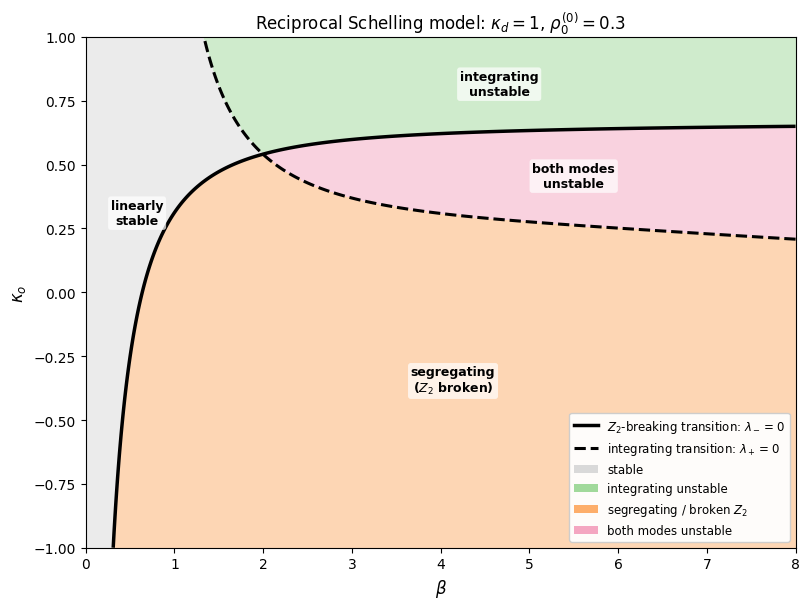

In [ ]:
#!/usr/bin/env python3

"""
Pure Schelling tree-level phase diagram.

We scan

    kappa = [[ 1,  x],
             [x,  1]]

in the (beta, x) plane, with D_V = 0.

The exact microscopic response matrix Theta^{ab}(rho) is used.

The linearized hydrodynamic matrix J determines the long-wavelength
eigenmodes.  We distinguish five regions:

    1. linearly stable, real modes
    2. linearly stable, oscillatory modes
    3. integrating-like stationary instability
    4. segregating-like stationary instability
    5. oscillatory/migrating instability

For a stationary unstable mode with right eigenvector v = (v_A,v_B),

    chi_v = 2 v_A v_B / (v_A^2 + v_B^2)

is used to classify the instability:

    chi_v > 0 : integrating-like
    chi_v < 0 : segregating-like

For an exactly A <-> B symmetric theory these reduce to the
symmetric (1,1) and antisymmetric (1,-1) modes, respectively.

Dependencies:
    numpy
    matplotlib
"""

from dataclasses import dataclass, replace
from math import factorial

import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# ============================================================================
# USER CONFIGURATION
# ============================================================================


KAPPA_D = 1.0

BETA_RANGE = (0.0, 8.0)
KAPPA_O_RANGE = (-1.0, 1.0)

N_BETA = 401
N_KAPPA_O = 401

# Overall time-scale normalization
D_A = 1.0
D_B = 1.0

# Pure Schelling
D_V = 0.0

# Symmetric homogeneous background
RHO_0 = 0.30
RHO_A = 0.5 * (1.0 - RHO_0)
RHO_B = 0.5 * (1.0 - RHO_0)

TOL = 1e-10

OUTPUT_FILE = "../images/pure_schelling_reciprocal_phase_diagram.png"
SHOW_FIGURE = True


# ============================================================================
# PARAMETERS
# ============================================================================

@dataclass
class Params:
    D_A: float = 1.0
    D_B: float = 1.0
    D_V: float = 0.0

    beta: float = 1.0

    rho_A: float = 0.35
    rho_B: float = 0.35

    @property
    def rho_0(self):
        return 1.0 - self.rho_A - self.rho_B


# ============================================================================
# MICROSCOPIC INTERACTION MATRIX
# ============================================================================

def kappa_from_x(x):
    """
    Non-reciprocal one-parameter family

        kappa = [[ 1,  x],
                 [-x,  1]]
    """

    return np.array(
        [
            [1.0,  x],
            [-x,   1.0],
        ],
        dtype=float,
    )

def kappa_from_offdiag(kappa_o):
    """
    Reciprocal Z2-symmetric interaction matrix

        kappa = [[kappa_d, kappa_o],
                 [kappa_o, kappa_d]]

    with fixed kappa_d = 1.
    """
    return np.array([
        [KAPPA_D, kappa_o],
        [kappa_o, KAPPA_D],
    ], dtype=float)


# ============================================================================
# EXACT MICROSCOPIC THETA MATRIX
# ============================================================================

def multinomial3(n, i, j):
    """
    n! / [i! j! (n-i-j)!]
    """

    k = n - i - j

    if min(i, j, k) < 0:
        return 0

    return (
        factorial(n)
        // (
            factorial(i)
            * factorial(j)
            * factorial(k)
        )
    )


def theta_matrix(
    beta,
    kappa,
    rho_A,
    rho_B,
):
    r"""
    Exact finite-spectator response matrix Theta^{ab}(rho).

    For the square-lattice geometry used in the derivation,

        Theta^{ab}
        =
        <
            tanh[ beta/2 (Delta + kappa^{ab}) ]
            -
            tanh[ beta/2 Delta ]
        >,

    where

        Delta
        =
        (m_A-n_A) kappa^{aA}
        +
        (m_B-n_B) kappa^{aB}.

    The average is over:
        2 destination-side spectators
        3 source-side spectators

    with probabilities rho_A, rho_B, rho_0.
    """

    rho_0 = 1.0 - rho_A - rho_B

    if (
        rho_A < 0.0
        or rho_B < 0.0
        or rho_0 < 0.0
    ):
        return np.full((2, 2), np.nan)

    Theta = np.zeros(
        (2, 2),
        dtype=float,
    )

    # ------------------------------------------------------------------
    # Destination-side spectators: 2 sites
    # ------------------------------------------------------------------

    for mA in range(3):

        for mB in range(3 - mA):

            m0 = 2 - mA - mB

            p_m = (
                multinomial3(2, mA, mB)
                * rho_A**mA
                * rho_B**mB
                * rho_0**m0
            )

            # ----------------------------------------------------------
            # Source-side spectators: 3 sites
            # ----------------------------------------------------------

            for nA in range(4):

                for nB in range(4 - nA):

                    n0 = 3 - nA - nB

                    p_n = (
                        multinomial3(3, nA, nB)
                        * rho_A**nA
                        * rho_B**nB
                        * rho_0**n0
                    )

                    weight = p_m * p_n

                    if weight == 0.0:
                        continue

                    # --------------------------------------------------
                    # Species a whose hopping rate responds
                    # --------------------------------------------------

                    for a in range(2):

                        delta = (
                            (mA - nA) * kappa[a, 0]
                            +
                            (mB - nB) * kappa[a, 1]
                        )

                        t0 = np.tanh(
                            0.5 * beta * delta
                        )

                        # ----------------------------------------------
                        # Density species b being varied
                        # ----------------------------------------------

                        for b in range(2):

                            t1 = np.tanh(
                                0.5
                                * beta
                                * (
                                    delta
                                    + kappa[a, b]
                                )
                            )

                            Theta[a, b] += (
                                weight
                                * (t1 - t0)
                            )

    return Theta


# ============================================================================
# LINEARIZED HYDRODYNAMIC MATRIX
# ============================================================================

def linear_matrix_J(
    p: Params,
    kappa: np.ndarray,
):
    """
    Linear q^2 transport matrix around a homogeneous state.
    """

    rho_A = p.rho_A
    rho_B = p.rho_B
    rho_0 = p.rho_0

    if (
        rho_A < 0.0
        or rho_B < 0.0
        or rho_0 < -1e-14
    ):
        return np.full((2, 2), np.nan)

    Theta = theta_matrix(
        beta=p.beta,
        kappa=kappa,
        rho_A=rho_A,
        rho_B=rho_B,
    )

    J = np.empty(
        (2, 2),
        dtype=float,
    )

    # AA
    J[0, 0] = (
        p.D_A * (1.0 - rho_B)
        + p.D_V * rho_B
        - 10.0
        * p.D_A
        * rho_0
        * rho_A
        * Theta[0, 0]
    )

    # AB
    J[0, 1] = (
        p.D_A * rho_A
        - p.D_V * rho_A
        - 10.0
        * p.D_A
        * rho_0
        * rho_A
        * Theta[0, 1]
    )

    # BA
    J[1, 0] = (
        p.D_B * rho_B
        - p.D_V * rho_B
        - 10.0
        * p.D_B
        * rho_0
        * rho_B
        * Theta[1, 0]
    )

    # BB
    J[1, 1] = (
        p.D_B * (1.0 - rho_A)
        + p.D_V * rho_A
        - 10.0
        * p.D_B
        * rho_0
        * rho_B
        * Theta[1, 1]
    )

    return J


# ============================================================================
# GRID EVALUATION
# ============================================================================
def evaluate_beta_kappa_grid(base, betas, kappa_os):

    shape = (len(kappa_os), len(betas))

    lambda_plus = np.full(shape, np.nan)
    lambda_minus = np.full(shape, np.nan)

    for ik, kappa_o in enumerate(kappa_os):

        kappa = kappa_from_offdiag(kappa_o)

        for ib, beta in enumerate(betas):

            p = replace(
                base,
                beta=float(beta),
                D_V=0.0,
            )

            J = linear_matrix_J(p, kappa)

            if not np.all(np.isfinite(J)):
                continue

            # In the Z2-symmetric reciprocal case:
            #
            # J = [[a,b],
            #      [b,a]]
            #
            # + mode: (1,1)
            # - mode: (1,-1)

            lambda_plus[ik, ib] = J[0, 0] + J[0, 1]
            lambda_minus[ik, ib] = J[0, 0] - J[0, 1]

    return {
        "lambda_plus": lambda_plus,
        "lambda_minus": lambda_minus,
    }

# ============================================================================
# MAIN PLOT
# ============================================================================
def main():

    from matplotlib.colors import ListedColormap, BoundaryNorm
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch

    TOL = 1e-10

    base = Params(
        D_A=D_A,
        D_B=D_B,
        D_V=0.0,
        beta=1.0,
        rho_A=RHO_A,
        rho_B=RHO_B,
    )

    betas = np.linspace(
        *BETA_RANGE,
        N_BETA,
    )

    kappa_os = np.linspace(
        *KAPPA_O_RANGE,
        N_KAPPA_O,
    )

    BETA, KAPPA_O = np.meshgrid(
        betas,
        kappa_os,
    )

    data = evaluate_beta_kappa_grid(
        base,
        betas,
        kappa_os,
    )

    lam_plus = data["lambda_plus"]
    lam_minus = data["lambda_minus"]


    # ============================================================
    # PHASE CLASSIFICATION
    # ============================================================

    # Both modes stable
    stable = (
        (lam_plus > TOL)
        & (lam_minus > TOL)
    )

    # Symmetric mode unstable only
    integrating = (
        (lam_plus < -TOL)
        & (lam_minus > TOL)
    )

    # Antisymmetric mode unstable only:
    # spontaneous A <-> B symmetry breaking
    segregating = (
        (lam_minus < -TOL)
        & (lam_plus > TOL)
    )

    # Both stationary modes unstable
    both_unstable = (
        (lam_plus < -TOL)
        & (lam_minus < -TOL)
    )


    # ============================================================
    # PHASE MAP
    # ============================================================

    phase = np.full_like(
        lam_plus,
        np.nan,
        dtype=float,
    )

    phase[stable] = 0
    phase[integrating] = 1
    phase[segregating] = 2
    phase[both_unstable] = 3


    phase_colors = [
        "#d9d9d9",   # stable
        "#a1d99b",   # integrating
        "#fdae6b",   # segregating
        "#f4a6c1",   # both unstable
    ]

    cmap = ListedColormap(
        phase_colors
    )

    norm = BoundaryNorm(
        [-0.5, 0.5, 1.5, 2.5, 3.5],
        cmap.N,
    )


    # ============================================================
    # FIGURE
    # ============================================================

    fig, ax = plt.subplots(
        figsize=(8.2, 6.2)
    )

    ax.pcolormesh(
        BETA,
        KAPPA_O,
        np.ma.masked_invalid(phase),
        cmap=cmap,
        norm=norm,
        shading="auto",
        alpha=0.50,
    )


    # ============================================================
    # INTEGRATING CRITICAL LINE
    #
    # lambda_+ = 0
    # ============================================================

    finite = lam_plus[
        np.isfinite(lam_plus)
    ]

    if (
        finite.size > 0
        and np.min(finite) < -TOL
        and np.max(finite) > TOL
    ):
        ax.contour(
            BETA,
            KAPPA_O,
            lam_plus,
            levels=[0.0],
            colors="black",
            linewidths=2.2,
            linestyles="--",
        )


    # ============================================================
    # SEGREGATION / Z2-BREAKING CRITICAL LINE
    #
    # lambda_- = 0
    # ============================================================

    finite = lam_minus[
        np.isfinite(lam_minus)
    ]

    if (
        finite.size > 0
        and np.min(finite) < -TOL
        and np.max(finite) > TOL
    ):
        ax.contour(
            BETA,
            KAPPA_O,
            lam_minus,
            levels=[0.0],
            colors="black",
            linewidths=2.5,
            linestyles="-",
        )


    # ============================================================
    # REGION LABEL HELPER
    # ============================================================

    def place_region_label(mask, text, min_fraction=0.01):

        iy, ix = np.where(mask)

        if len(ix) == 0:
            return

        if len(ix) / mask.size < min_fraction:
            return

        beta_points = BETA[iy, ix]
        kappa_points = KAPPA_O[iy, ix]

        beta_c = np.mean(beta_points)
        kappa_c = np.mean(kappa_points)

        dbeta = (
            (beta_points - beta_c)
            /
            (BETA_RANGE[1] - BETA_RANGE[0])
        )

        dkappa = (
            (kappa_points - kappa_c)
            /
            (KAPPA_O_RANGE[1] - KAPPA_O_RANGE[0])
        )

        i_best = np.argmin(
            dbeta**2 + dkappa**2
        )

        ax.text(
            beta_points[i_best],
            kappa_points[i_best],
            text,
            ha="center",
            va="center",
            fontsize=9,
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.22",
                facecolor="white",
                edgecolor="none",
                alpha=0.70,
            ),
            zorder=10,
        )


    # ============================================================
    # REGION LABELS
    # ============================================================

    place_region_label(
        stable,
        "linearly\nstable",
    )

    place_region_label(
        integrating,
        "integrating\nunstable",
    )

    place_region_label(
        segregating,
        r"segregating"
        "\n"
        r"($Z_2$ broken)",
    )

    place_region_label(
        both_unstable,
        "both modes\nunstable",
    )


    # ============================================================
    # LEGEND
    # ============================================================

    line_handles = [
        Line2D(
            [0], [0],
            color="black",
            linewidth=2.5,
            linestyle="-",
            label=r"$Z_2$-breaking transition: $\lambda_-=0$",
        ),

        Line2D(
            [0], [0],
            color="black",
            linewidth=2.2,
            linestyle="--",
            label=r"integrating transition: $\lambda_+=0$",
        ),
    ]

    phase_handles = [
        Patch(
            facecolor=phase_colors[0],
            edgecolor="none",
            label="stable",
        ),

        Patch(
            facecolor=phase_colors[1],
            edgecolor="none",
            label="integrating unstable",
        ),

        Patch(
            facecolor=phase_colors[2],
            edgecolor="none",
            label=r"segregating / broken $Z_2$",
        ),

        Patch(
            facecolor=phase_colors[3],
            edgecolor="none",
            label="both modes unstable",
        ),
    ]

    ax.legend(
        handles=line_handles + phase_handles,
        fontsize=8.5,
        loc="lower right",
        framealpha=0.95,
    )


    # ============================================================
    # AXES
    # ============================================================

    ax.set_xlabel(
        r"$\beta$",
        fontsize=12,
    )

    ax.set_ylabel(
        r"$\kappa_o$",
        fontsize=12,
    )

    ax.set_xlim(
        *BETA_RANGE
    )

    ax.set_ylim(
        *KAPPA_O_RANGE
    )

    ax.set_title(
        r"Reciprocal Schelling model: "
        r"$\kappa_d=1$, "
        # r"$D_V=0$, "
        + rf"$\rho_0^{{(0)}}={RHO_0:g}$"
    )


    # ============================================================
    # DIAGNOSTICS
    # ============================================================

    print(
        "lambda+ range:",
        np.nanmin(lam_plus),
        np.nanmax(lam_plus),
    )

    print(
        "lambda- range:",
        np.nanmin(lam_minus),
        np.nanmax(lam_minus),
    )


    # ============================================================
    # SAVE
    # ============================================================

    fig.tight_layout()

    fig.savefig(
        OUTPUT_FILE,
        dpi=300,
        bbox_inches="tight",
    )

    print(f"Saved: {OUTPUT_FILE}")

    if SHOW_FIGURE:
        plt.show()

# ============================================================================
# RUN
# ============================================================================

if __name__ == "__main__":
    main()